In [75]:
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import folium

In [76]:
#read in data
tables = [pq.read_table('yellow_tripdata_2025-06.parquet').to_pandas(),  
          pq.read_table('yellow_tripdata_2025-07.parquet').to_pandas()]

df = pd.concat(tables, ignore_index=True)
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 8221923 entries, 0 to 8221922
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee            float64   

In [77]:
#first, remove all fares and distances <=0 to limit skew
df = df[df["total_amount"]>0]
df = df[df["fare_amount"]>0]
df = df[df["trip_distance"]>0]

#remove all disputed and no charge trips
df = df[df["payment_type"]!=3]
df = df[df["payment_type"]!=4]

#filling passenger coutn w[ith one
modeVal = df["passenger_count"].mode()[0]
df['passenger_count'] = df["passenger_count"].fillna(modeVal)

#filling other missing values
df["RatecodeID"] = df["RatecodeID"].fillna(99) # RatecodeID with 99
df["store_and_fwd_flag"] = df["store_and_fwd_flag"].fillna('N') #store_and_fwd_flag with 'N'
df["congestion_surcharge"] = df["congestion_surcharge"].fillna(0) #congestion_surcharge with 0
df["Airport_fee"] = df["Airport_fee"].fillna(0) #Airport_fee with 0

#checking pickup and dropoff correctness
# Keep only rows where dropoff is strictly AFTER pickup
df = df[df["tpep_pickup_datetime"] < df["tpep_dropoff_datetime"]]
df = df[df['tpep_pickup_datetime'].dt.month > 5]
df = df[df['tpep_pickup_datetime'].dt.month < 8]

df.isna().sum()

VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
RatecodeID               0
store_and_fwd_flag       0
PULocationID             0
DOLocationID             0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
congestion_surcharge     0
Airport_fee              0
cbd_congestion_fee       0
dtype: int64

In [79]:
#add month column
df["month"] = df["tpep_pickup_datetime"].dt.month_name()
df = df[df["month"].isin(["June", "July"])] #clean to just june, july

#add day of week column
df["day_of_week"] = df["tpep_pickup_datetime"].dt.day_name()

#add hour column
df["hour"] = df["tpep_pickup_datetime"].dt.hour

#add borough column using zone_lookup csv
zone_lookup = pd.read_csv('taxi_zone_lookup.csv')
zone_lookup = zone_lookup.rename(columns={"Borough": "borough"})
zone_lookup['PULocationID'] = zone_lookup['LocationID'].astype(int)

lookup_dict = zone_lookup.set_index("PULocationID")["borough"]
df["borough"] = df["PULocationID"].map(lookup_dict).astype('category')
df['borough'] = df['borough'].fillna('Unknown')

In [80]:
#fixing data types:
df["passenger_count"] = df["passenger_count"].astype(int)
df["payment_type"] = df["payment_type"].astype(int)
df["RatecodeID"] = df["RatecodeID"].astype(int)
df['PULocationID'] = df["PULocationID"].astype(int)
df['DOLocationID'] = df["DOLocationID"].astype(int)

to_cats = ["store_and_fwd_flag",  "RatecodeID", "improvement_surcharge", "congestion_surcharge", "Airport_fee", "cbd_congestion_fee", "payment_type", "VendorID"]
df[to_cats] = df[to_cats].astype("category")

for cat in to_cats:
    print(cat, "categories", df[cat].cat.categories)

store_and_fwd_flag categories Index(['N', 'Y'], dtype='str')
RatecodeID categories Index([1, 2, 3, 4, 5, 6, 99], dtype='int64')
improvement_surcharge categories Index([0.0, 0.3, 1.0], dtype='float64')
congestion_surcharge categories Index([0.0, 0.75, 1.0, 2.5], dtype='float64')
Airport_fee categories Index([0.0, 1.75], dtype='float64')
cbd_congestion_fee categories Index([-0.75, 0.0, 0.75, 1.25, 1.5], dtype='float64')
payment_type categories Index([0, 1, 2, 5], dtype='int64')
VendorID categories Index([1, 2, 6], dtype='int32')


In [81]:
#make a "typical DF" with distance less than or equal to 30 miles and price less than or equal to 100 dollars
typicalDF = df[(df["total_amount"] <= 100) & (df["trip_distance"] <= 30)]
typicalDF["month"] = typicalDF["tpep_pickup_datetime"].dt.month

boroughs= typicalDF['borough'].unique()

### Exploratory Plots:

/var/folders/4l/47r63rdj4n9d0_9nlnjm4gqr0000gn/T/ipykernel_3331/51690511.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(plot_data, labels=boroughs)


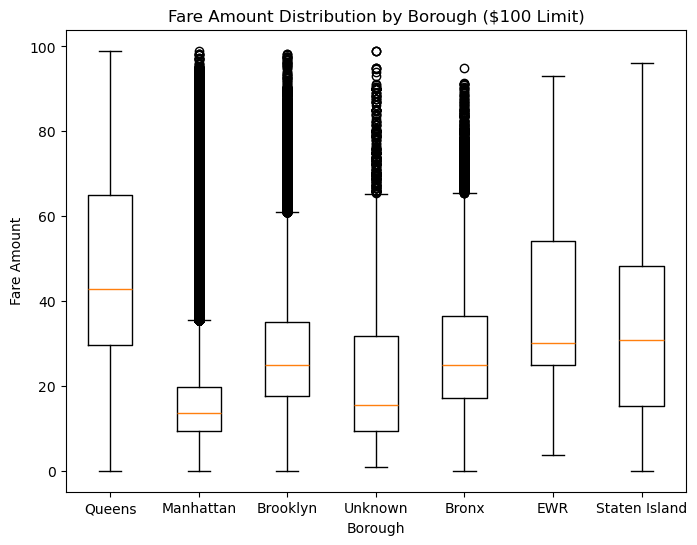

In [82]:
#fare amount boxplot by borough
plot_data = [typicalDF[typicalDF['borough']==b]['fare_amount'] for b in boroughs]

plt.figure(figsize=(8,6))
plt.boxplot(plot_data, labels=boroughs)
plt.title("Fare Amount Distribution by Borough ($100 Limit)")
plt.xlabel("Borough")
plt.ylabel("Fare Amount")
plt.show()

/var/folders/4l/47r63rdj4n9d0_9nlnjm4gqr0000gn/T/ipykernel_3331/3402534965.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(plot_data, labels=boroughs)


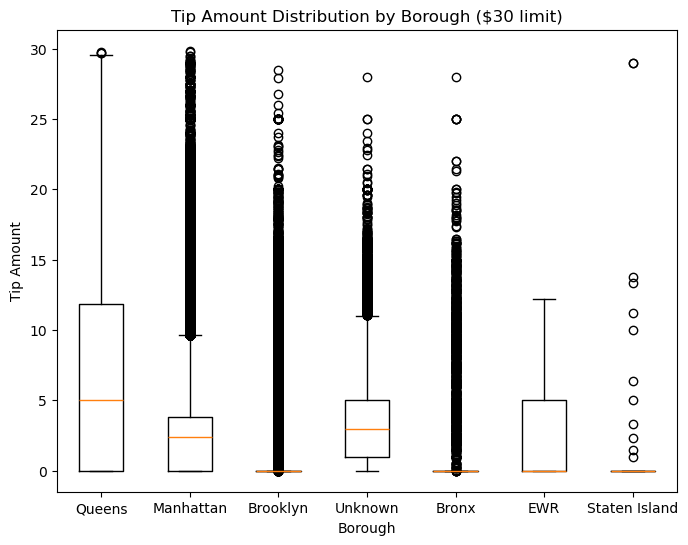

In [83]:
#tip amount boxplot by borough
plot_df = typicalDF[typicalDF['tip_amount']<30]
plot_data = [plot_df[plot_df['borough']==b]['tip_amount'] for b in boroughs]

plt.figure(figsize=(8,6))
plt.boxplot(plot_data, labels=boroughs)
plt.title("Tip Amount Distribution by Borough ($30 limit)")
plt.ylabel("Tip Amount")
plt.xlabel("Borough")
plt.show()

/var/folders/4l/47r63rdj4n9d0_9nlnjm4gqr0000gn/T/ipykernel_3331/3691381222.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(plot_data, labels=boroughs)


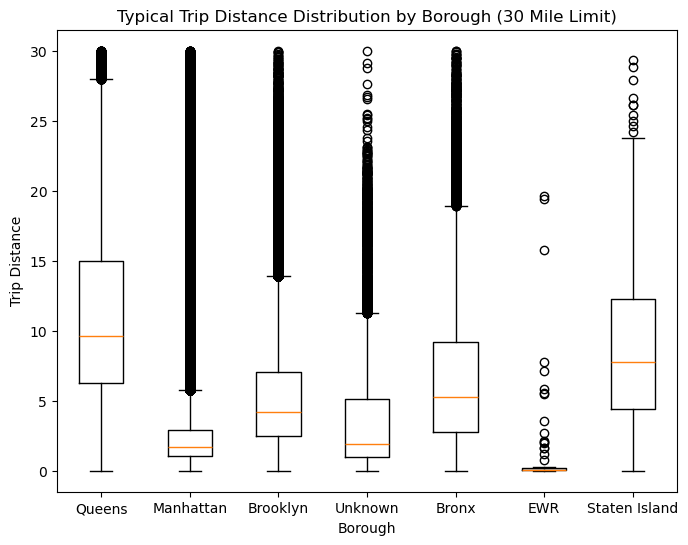

In [84]:
#distance boxplot by borough
plot_data = [typicalDF[typicalDF['borough']==b]['trip_distance'] for b in boroughs]

plt.figure(figsize=(8,6))
plt.boxplot(plot_data, labels=boroughs)
plt.title("Typical Trip Distance Distribution by Borough (30 Mile Limit)")
plt.ylabel("Trip Distance")
plt.xlabel("Borough")
plt.show()

### Final visualizations

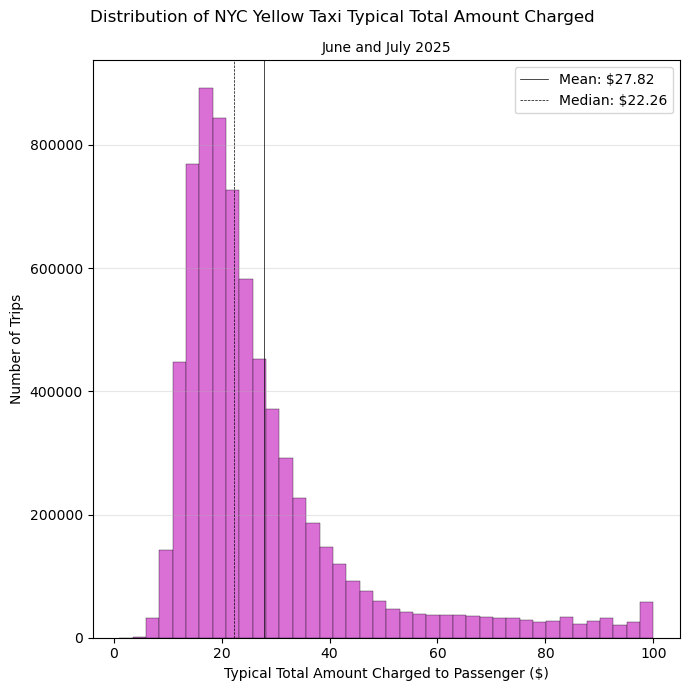

In [85]:
#histogram for total amount charged
meanVal=typicalDF["total_amount"].mean()
medianVal=typicalDF["total_amount"].median()

plt.figure(figsize=(7,7))
plt.hist(typicalDF["total_amount"], color="orchid", edgecolor="black", lw=0.25, bins=40)
plt.suptitle("Distribution of NYC Yellow Taxi Typical Total Amount Charged ")
plt.title("June and July 2025", fontsize=10)
plt.xlabel("Typical Total Amount Charged to Passenger ($)")
plt.ylabel("Number of Trips")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.axvline(meanVal, color='black', linestyle='solid', linewidth=0.5, label=f'Mean: ${meanVal:.2f}')
plt.axvline(medianVal, color="black", linestyle="dashed", linewidth=0.5, label=f'Median: ${medianVal:.2f}')
plt.legend()
plt.savefig('totalAmntHist.png')
plt.show()

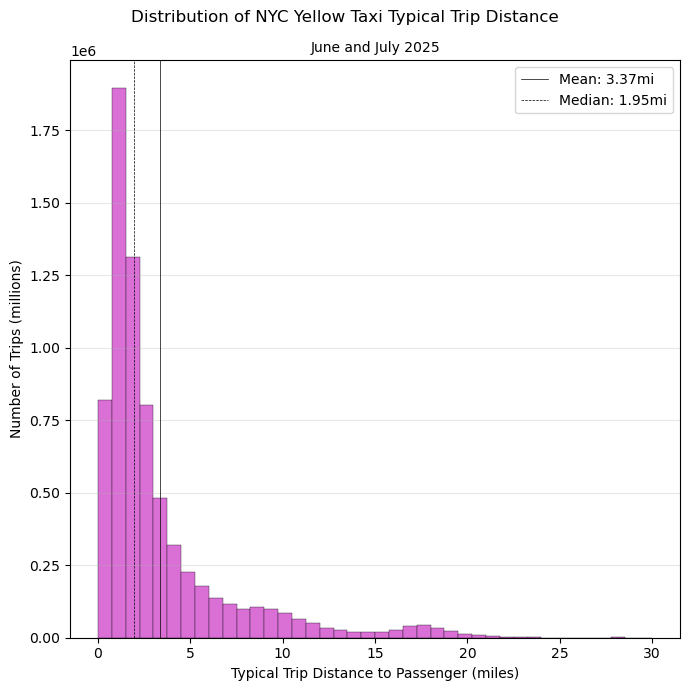

In [86]:
#histogram for distance
meanVal=typicalDF["trip_distance"].mean()
medianVal=typicalDF["trip_distance"].median()

plt.figure(figsize=(7,7))
plt.hist(typicalDF["trip_distance"], color="orchid", edgecolor="black", lw=0.25, bins=40)
plt.suptitle("Distribution of NYC Yellow Taxi Typical Trip Distance")
plt.title("June and July 2025", fontsize=10)
plt.xlabel("Typical Trip Distance to Passenger (miles)")
plt.ylabel("Number of Trips (millions)")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.axvline(meanVal, color='black', linestyle='solid', linewidth=0.5, label=f'Mean: {meanVal:.2f}mi')
plt.axvline(medianVal, color="black", linestyle="dashed", linewidth=0.5, label=f'Median: {medianVal:.2f}mi')
plt.legend()
plt.savefig('tripDistHist.png')
plt.show()

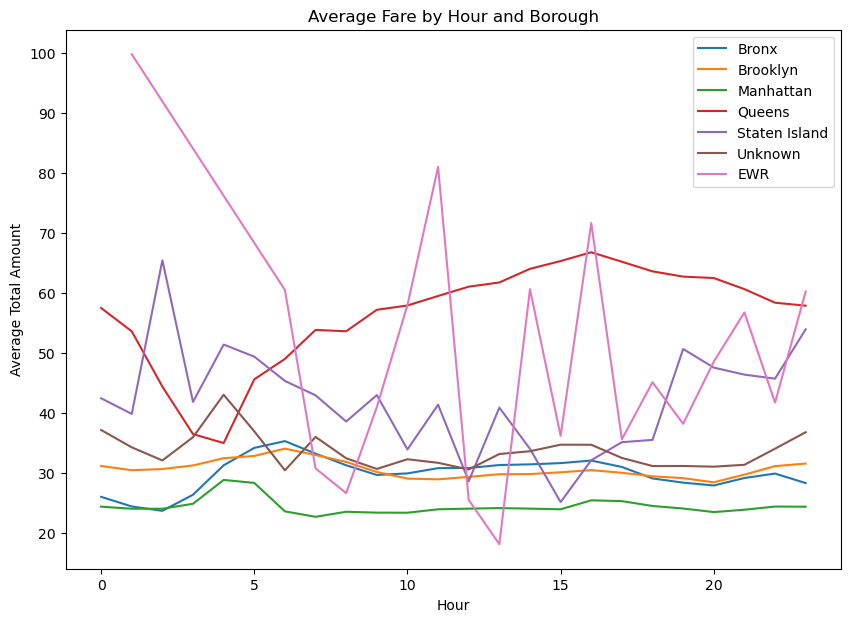

In [97]:
#lineplot of average total amount by borough by hour
avg = typicalDF.groupby(["hour", "borough"])["total_amount"].mean().reset_index()

plt.figure(figsize=(10,7))
for b in avg["borough"].unique():
    subset = avg[avg["borough"] == b]
    plt.plot(subset["hour"], subset["total_amount"], label=b)

plt.title("Average Fare by Hour and Borough")
plt.xlabel("Hour")
plt.ylabel("Average Total Amount")
plt.legend()
plt.savefig('FarebyHourandBorough_lineplot.png')
plt.show()

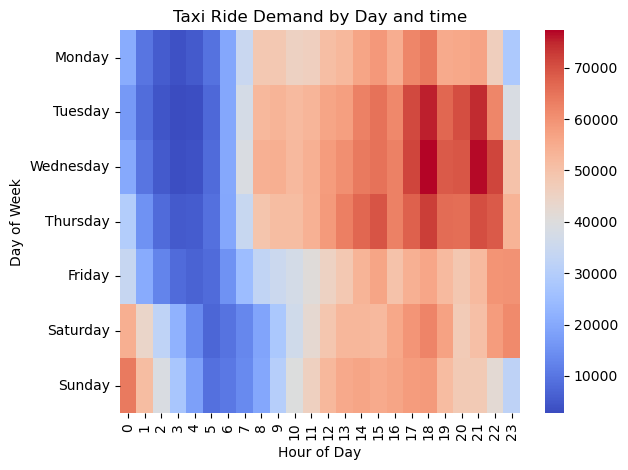

In [96]:
#heatmap
pivot = typicalDF.pivot_table(index="day_of_week", columns="hour", values="tpep_pickup_datetime", aggfunc="count")
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = pivot.reindex(order)

sns.heatmap(pivot, cmap="coolwarm")
plt.title("Taxi Ride Demand by Day and time")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.savefig('Demand_heatmap.png')
plt.show()

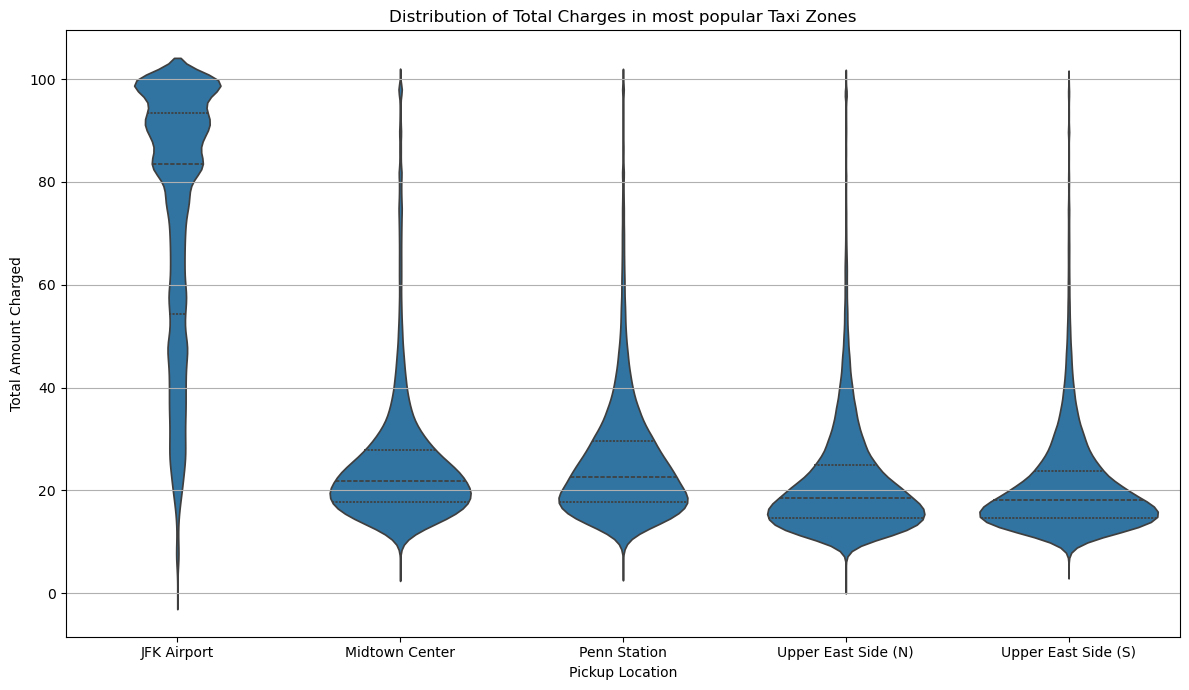

In [95]:
#violin plot
location_names = {132: "JFK Airport",
                  161: "Midtown Center",
                  186: "Penn Station",
                  236: "Upper East Side (N)", 
                  237: "Upper East Side (S)"}

df_filtered = typicalDF[typicalDF['PULocationID'].isin(location_names.keys())].copy()
df_filtered['Location_Name'] = df_filtered['PULocationID'].map(location_names)

plt.figure(figsize=(12, 7))
sns.violinplot(data=df_filtered, x='Location_Name', y='total_amount', inner="quartile", order=["JFK Airport", 
                                                                                               "Midtown Center", 
                                                                                               "Penn Station", 
                                                                                               "Upper East Side (N)", 
                                                                                               "Upper East Side (S)"])

plt.title('Distribution of Total Charges in most popular Taxi Zones')
plt.xlabel('Pickup Location')
plt.ylabel('Total Amount Charged')
plt.grid(axis='y')
plt.tight_layout()
plt.savefig('total_charge_violinplot.png')
plt.show()

### interactive/geospatial

In [91]:
nyc = gpd.read_file('NYC_Taxi_Zones.geojson')
nyc = nyc.rename(columns={"locationid": "LocationID"})

# reduce data frame and fix datatype
nyc=nyc[['LocationID', 'borough', 'geometry']]
nyc['LocationID'] = nyc['LocationID'].astype(int)

In [92]:
# aggregate, group, reduce dataframe and fix type
boroughDF = typicalDF.groupby(['PULocationID', 'borough']).agg({'trip_distance': 'mean', 'total_amount': 'mean'}).reset_index()
boroughDF = boroughDF.rename(columns={'PULocationID' : 'LocationID'})
boroughDF=boroughDF[['LocationID', 'trip_distance', 'total_amount']]

#rounding
boroughDF['trip_distance']=boroughDF['trip_distance'].round(2)
boroughDF['total_amount']=boroughDF['total_amount'].round(2)

In [93]:
# merge nyc with boroughDF
nyc_data = nyc.merge(boroughDF, on='LocationID', how='left')

#for plot
color_map = {
    "Manhattan": "red",
    "Brooklyn": "blue",
    "Queens": "green",
    "Bronx": "orange",
    "Staten Island": "purple"
}

In [94]:
map_nyc = folium.Map(location=[40.7128, -74.0060], zoom_start=11) #set center and zoom

folium.GeoJson(
    nyc_data,
    tooltip=folium.GeoJsonTooltip(fields=["LocationID", "borough", "trip_distance", 'total_amount'], #hover data
                                  aliases=["Location ID", "Borough", 'mean trip distance', 'mean total amount charged']), #hover names
                                  zoom_on_click=True,
                                  style_function=lambda feature: {
                                      "fillColor": color_map.get(feature["properties"]["borough"], "grey"),
                                      'weight': 1, #border weight
                                      'color' : 'black' #border color
                                      }).add_to(map_nyc)

map_nyc.save('nyc_map.html')